In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from scipy import stats
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re
from random import sample

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = "C:\\Users\\olesk\\ECM_mod_output"

rcParams.update({'figure.autolayout': True})


In [3]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

In [4]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

In [5]:
from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-9
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    ln_em2 = np.log(emg2)
    return ln_em2.sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def crit(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    
    LL2 = logl_emg2v2(log_par, data)
    negLL2 = -LL2      
    return negLL2

def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth


In [6]:
IMT_DATADIR = Path("C:\\Users\\olesk\\ECM_mod_output")

In [7]:
file_location = os.path.join(IMT_DATADIR,'G1s*cycdi*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

g1_cycdi = []
for f in filenames:
    tmp_df = pd.read_csv(f,header=None).transpose()
#     tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    g1_cycdi.append(tmp_df)

In [8]:
file_location = os.path.join(IMT_DATADIR,'G1s*orig*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames

g1_orig = []
for f in filenames:
    tmp_df = pd.read_csv(f,header=None).transpose()
#     tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    g1_orig.append(tmp_df)

In [9]:
filenames

['C:\\Users\\olesk\\ECM_mod_output\\G1s_0.6 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\G1s_0.6 kPa erlotinib_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\G1s_4 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\G1s_4 kPa erlotinib_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\G1s_55 kPa DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\G1s_55 kPa erlotinib_param_orig.csv']

In [10]:
centers = np.arange(0.5, 100.5, 1)

Text(0.015, 75, '$\\mu = 11.73$\n$\\sigma = 4.76$\n$\\lambda = 0.04$')

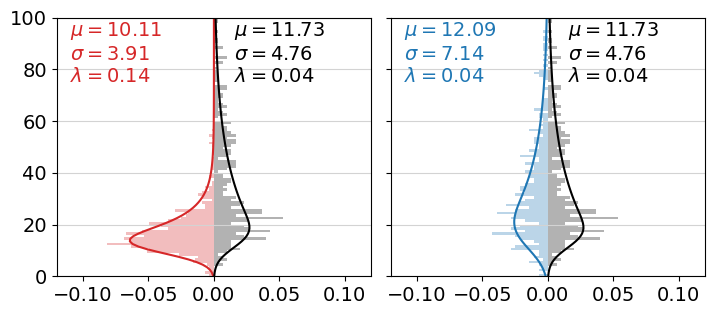

In [15]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 2, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

data = np.array(g1_orig[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2, size=14)


data = np.array(g1_cycdi[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color='black', alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color='black')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color='black', size=14)

data = np.array(g1_orig[1])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1, size=14)


data = np.array(g1_cycdi[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color='black', alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color='black')
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].axes.yaxis.set_ticklabels([])
axes[1].text(0.015, 75, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color='black', size=14)


In [45]:
sample1 = sample(list(g1_orig[5]), 250)
sample2 = sample(list(g1_cycdi[5]), 250)
stats.ks_2samp(sample1, sample2)

KstestResult(statistic=0.464, pvalue=1.1415152730164187e-24, statistic_location=306, statistic_sign=-1)

In [42]:
sample1 = sample(list(g1_orig[1]), 250)
sample2 = sample(list(g1_cycdi[5]), 250)
stats.ks_2samp(sample1, sample2)

KstestResult(statistic=0.068, pvalue=0.6109101078019121, statistic_location=222, statistic_sign=1)

In [39]:
g1_orig[1].size

286